# Modelos Matemáticos y Estadísticos Clásicos
## Diplomado en Data Science 2026

---

## Taller 2


**Integrantes**:

-
-
-


## Caso: Empresa de comercio electrónico

Formas parte del equipo de Data Science de una empresa de comercio electrónico. Un analista del equipo ha estado trabajando en distintos problemas relacionados con operación, tiempos de entrega, riesgo de atraso y planificación de demanda.

Tu tarea **no consiste solamente en ejecutar modelos**. Durante esta evaluación deberás revisar el trabajo del analista, decidir si sus conclusiones son correctas, proponer mejoras cuando corresponda y justificar tus decisiones.

### Objetivos evaluados

Se espera que seas capaz de:

- identificar qué herramienta estadística es apropiada para una pregunta;
- distinguir entre una asociación descriptiva, evidencia estadística y causalidad;
- interpretar correctamente resultados y métricas;
- detectar cuándo una conclusión **sí** está respaldada por los datos y cuándo **no**;
- comparar modelos y justificar cuál utilizarías.

### Importante

- El código de preparación de datos ya está entregado y **no forma parte de la evaluación**.
- Puedes agregar las celdas de código o texto que estimes necesarias.
- Toda conclusión debe estar respaldada por resultados reproducibles en el notebook.
- No se evaluará la cantidad de código, sino la calidad del análisis.

### Criterio de desarrollo

Este notebook mantiene la estructura del enunciado y desarrolla cada bloque con el enfoque trabajado en las clases del diplomado. La idea no es elegir un modelo solo porque entregue un número aparentemente mejor, sino distinguir entre descripción, evidencia estadística y causalidad, revisar supuestos, privilegiar modelos parsimoniosos y evaluar la capacidad predictiva con métricas coherentes con cada problema.

En las interpretaciones se usa un lenguaje aplicado: los resultados se explican en el contexto de pedidos, costo de despacho, atraso y demanda, evitando conclusiones más fuertes de lo que permiten los datos.


---

#  Preparación de datos

El siguiente código construye una tabla analítica a nivel de pedido a partir de cuatro tablas de origen.

**No es necesario modificar esta sección.**


In [1]:
from pathlib import Path
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import statsmodels.api as sm
import statsmodels.formula.api as smf

from scipy import stats
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
    RocCurveDisplay,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    root_mean_squared_error
)

from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Los cuatro CSV deben estar en la misma carpeta del notebook.
# También se considera /mnt/data para que el notebook pueda ejecutarse en este entorno.
def buscar_archivo(nombre):
    candidatos = [
        Path(nombre),
        Path(".") / nombre,
        Path("/mnt/data") / nombre
    ]
    for ruta in candidatos:
        if ruta.exists():
            return ruta
    raise FileNotFoundError(
        f"No se encontró {nombre}. Deja los CSV en la misma carpeta que el notebook."
    )

RUTA_CUSTOMERS = buscar_archivo("customers - customers(1).csv")
RUTA_ORDER_ITEMS = buscar_archivo("order_items - order_items(1).csv")
RUTA_ORDERS = buscar_archivo("orders - orders(1).csv")
RUTA_PRODUCTS = buscar_archivo("products - products(1).csv")

customers = pd.read_csv(RUTA_CUSTOMERS)
order_items = pd.read_csv(RUTA_ORDER_ITEMS)
orders = pd.read_csv(RUTA_ORDERS)
products = pd.read_csv(RUTA_PRODUCTS)

print("customers:", customers.shape)
print("order_items:", order_items.shape)
print("orders:", orders.shape)
print("products:", products.shape)


customers: (15150, 5)
order_items: (16767, 7)
orders: (15000, 8)
products: (9208, 9)


In [2]:
for col in [
    "order_item_id",
    "price",
    "freight_value"
]:
    if col in order_items.columns:
        order_items[col] = pd.to_numeric(
            order_items[col],
            errors="coerce"
        )

for col in [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]:
    if col in products.columns:
        products[col] = pd.to_numeric(
            products[col],
            errors="coerce"
        )


# Fechas
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    if col in orders.columns:
        orders[col] = pd.to_datetime(
            orders[col],
            errors="coerce",
            format="mixed"
        )

# Variables geométricas de productos
for col in [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]:
    if col in products.columns:
        products[col] = pd.to_numeric(products[col], errors="coerce")

if all(c in products.columns for c in ["product_length_cm", "product_height_cm", "product_width_cm"]):
    products["product_volume_cm3"] = (
        products["product_length_cm"]
        * products["product_height_cm"]
        * products["product_width_cm"]
    )

# Enriquecer ítems con atributos de producto
items_prod = order_items.merge(
    products[
        [c for c in [
            "product_id",
            "product_category_name",
            "product_weight_g",
            "product_volume_cm3"
        ] if c in products.columns]
    ],
    on="product_id",
    how="left"
)

# Agregación a nivel de pedido
agg_dict = {
    "n_items": ("order_item_id", "count"),
    "total_price": ("price", "sum"),
    "total_freight": ("freight_value", "sum"),
    "avg_item_price": ("price", "mean"),
    "n_products": ("product_id", "nunique"),
}

if "product_category_name" in items_prod.columns:
    agg_dict["n_categories"] = ("product_category_name", "nunique")
if "product_weight_g" in items_prod.columns:
    agg_dict["total_weight_g"] = ("product_weight_g", "sum")
if "product_volume_cm3" in items_prod.columns:
    agg_dict["total_volume_cm3"] = ("product_volume_cm3", "sum")

order_agg = (
    items_prod
    .groupby("order_id")
    .agg(**agg_dict)
    .reset_index()
)

# Tabla analítica
df = (
    orders
    .merge(customers, on="customer_id", how="left")
    .merge(order_agg, on="order_id", how="left")
)

# Variables derivadas
df["purchase_date"] = df["order_purchase_timestamp"].dt.floor("D")
df["purchase_weekday"] = df["order_purchase_timestamp"].dt.day_name()
df["purchase_month"] = df["order_purchase_timestamp"].dt.to_period("M").astype(str)
df["is_weekend_purchase"] = df["order_purchase_timestamp"].dt.dayofweek.ge(5).astype(int)

df["delivery_days"] = (
    df["order_delivered_customer_date"] - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

df["delay_days"] = (
    df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

df["days_to_carrier"] = (
    df["order_delivered_carrier_date"]
    - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400


df["remaining_days"] = (
    df["order_estimated_delivery_date"]
    - df["order_delivered_carrier_date"]
).dt.total_seconds() / 86400

df["approval_hours"] = (
    df["order_approved_at"]
    - df["order_purchase_timestamp"]
).dt.total_seconds() / 3600


df["late_delivery"] = np.where(
    df["order_delivered_customer_date"].notna()
    & df["order_estimated_delivery_date"].notna(),
    (df["delay_days"] > 0).astype(int),
    np.nan
)

df["freight_ratio"] = df["total_freight"] / df["total_price"].replace(0, np.nan)

# Solo pedidos entregados para análisis de tiempos
delivered = df[
    (df["order_status"] == "delivered")
    & df["delivery_days"].notna()
].copy()

print("Tabla analítica:", df.shape)
print("Pedidos entregados:", delivered.shape)

display(delivered.head())


Tabla analítica: (15150, 31)
Pedidos entregados: (14688, 31)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,n_items,total_price,total_freight,avg_item_price,n_products,n_categories,total_weight_g,total_volume_cm3,purchase_date,purchase_weekday,purchase_month,is_weekend_purchase,delivery_days,delay_days,days_to_carrier,remaining_days,approval_hours,late_delivery,freight_ratio
0,3b14820d642ea72e95df3289b6539c1c,4248fddd68e3375c24e743290ce2d9fa,delivered,2018-04-02 13:01:06,2018-04-02 13:10:21,2018-04-04 23:42:34,2018-04-12 17:12:13,2018-04-23,a79c62e50e66e1036ba2cb2e5e00aff3,37190,tres pontas,MG,1.000,75.900,19.500,75.900,1.000,1.000,700.000,"6,912.000",2018-04-02,Monday,2018-04,0,10.174,-10.283,2.445,18.012,0.154,0.000,0.257
1,8a795486f112df15565463862960aa40,e093120ffd5c259e2decb4ff5266f0dd,delivered,2018-05-20 20:28:32,2018-05-22 09:36:09,2018-05-22 15:48:00,2018-06-01 11:50:31,2018-05-29,81ec41f3b0c51a9df15c5957140686fa,13084,campinas,SP,1.000,95.900,11.300,95.900,1.000,1.000,"1,400.000","27,000.000",2018-05-20,Sunday,2018-05,1,11.640,3.493,1.805,6.342,37.127,1.000,0.118
2,7aa2471c1e8d0cd89eec9459fde59414,0eb400f3e6d2f08e70d2ab5af9c203f4,delivered,2017-09-18 19:09:52,2017-09-20 02:10:42,2017-09-21 19:37:10,2017-09-27 19:09:10,2017-10-04,c64b0bf5855e1d6ba223d649298c2915,36889,muriae,MG,1.000,81.000,42.710,81.000,1.000,1.000,"18,100.000","4,332.000",2017-09-18,Monday,2017-09,0,9.000,-6.202,3.019,12.183,31.014,0.000,0.527
3,95cf53396116b5dd518b5ba1c11a0bb5,3b2e666d92ce663a2f35ba3a6bb5df6a,delivered,2017-04-21 19:31:13,2017-04-21 19:45:10,2017-04-25 13:08:20,2017-05-04 16:46:54,2017-05-19,4113a7e912e87f632986e0562da140c7,74075,goiania,GO,1.000,59.000,17.840,59.000,1.000,1.000,275.000,"1,936.000",2017-04-21,Friday,2017-04,0,12.886,-14.301,3.734,23.453,0.233,0.000,0.302
4,6c5eb0920626d3ff5588d03d6f2d4936,1b83beaaa59c8cdfe738f7ead2517da8,delivered,2018-03-15 15:22:28,2018-03-17 03:08:57,2018-03-19 21:14:58,2018-05-03 11:29:52,2018-04-30,d69a93bce76b26886f72125e60b01cec,69040,manaus,AM,1.000,69.900,57.040,69.900,1.000,1.000,"1,200.000","21,000.000",2018-03-15,Thursday,2018-03,0,48.838,3.479,4.245,41.115,35.775,1.000,0.816


### Diccionario resumido de la tabla analítica

| Variable | Descripción |
|---|---|
| `order_id` | Identificador del pedido |
| `customer_state` | Estado/región del cliente |
| `purchase_date` | Fecha de compra |
| `purchase_weekday` | Día de la semana de compra |
| `is_weekend_purchase` | 1 si la compra se realizó sábado o domingo |
| `n_items` | Número de ítems del pedido |
| `n_products` | Número de productos distintos |
| `n_categories` | Número de categorías distintas, si está disponible |
| `total_price` | Valor total de los productos |
| `total_freight` | Valor total del despacho |
| `avg_item_price` | Precio promedio de los ítems |
| `total_weight_g` | Peso total aproximado de los productos |
| `total_volume_cm3` | Volumen total aproximado |
| `delivery_days` | Días transcurridos desde compra hasta entrega |
| `delay_days` | Días de diferencia respecto de la fecha comprometida |
| `days_to_carrier` | Número de días transcurridos desde que se realiza la compra hasta que el pedido es entregado al transportista. |
| `remaining_days` | Número de días disponibles entre la entrega del pedido al transportista y la fecha estimada de entrega al cliente. |
| `approval_hours` | Número de horas transcurridas desde que se realiza la compra hasta que el pedido es aprobado. |
| `late_delivery` | 1 si el pedido llegó después de la fecha comprometida |
| `freight_ratio` | Costo de despacho dividido por valor de productos |

---




## Primer bloque (20 puntos)

El analista preparó la siguiente tabla cruzada entre **tamaño del pedido** y **atraso**.

Primero creó dos grupos:

- `1_item`: pedidos con un solo ítem;
- `2_o_mas`: pedidos con dos o más ítems.

In [3]:
analisis_1 = delivered[
    delivered["late_delivery"].notna()
    & delivered["n_items"].notna()
].copy()

analisis_1["grupo_items"] = np.where(
    analisis_1["n_items"] == 1,
    "1_item",
    "2_o_mas"
)

tabla = pd.crosstab(
    analisis_1["grupo_items"],
    analisis_1["late_delivery"]
)

tabla


late_delivery,0.000,1.000
grupo_items,,
1_item,12054,1080
2_o_mas,1309,96


El analista luego calculó dos tablas:



In [4]:
# Tabla A
tabla_fila = pd.crosstab(
    analisis_1["grupo_items"],
    analisis_1["late_delivery"],
    normalize="index"
)

tabla_fila


late_delivery,0.000,1.000
grupo_items,,
1_item,0.918,0.082
2_o_mas,0.932,0.068


In [5]:
# Tabla B
tabla_columna = pd.crosstab(
    analisis_1["grupo_items"],
    analisis_1["late_delivery"],
    normalize="columns"
)

tabla_columna


late_delivery,0.000,1.000
grupo_items,,
1_item,0.902,0.918
2_o_mas,0.098,0.082



El analista afirma:

> "El analista observa que en la Tabla B el valor asociado a 1_item y late_delivery=1 es 0,918 y concluye que “los pedidos de un ítem tienen 91,8% de probabilidad de atraso”. ¿Es correcta esta interpretación?"


1. Explique qué representa el valor 0,082 de la Tabla A.  

2. Explique qué representa el valor 0,918 de la Tabla B.

3. ¿Cuál de las dos tablas permite comparar la probabilidad de atraso entre
pedidos de 1 ítem y de 2 o más ítems?

4. ¿Los resultados descriptivos apoyan la hipótesis del analista?

5. Evalúe si la diferencia observada es solo una cuestión de la muestra. Considere y explicite los supuestos/límites necesarios.

6. ¿Puede concluir que cambiar el número de ítems de un pedido modifica causalmente su probabilidad de atraso? Explique.

### Tu análisis


In [6]:
# 1) Comparación descriptiva de las probabilidades de atraso
riesgo_atraso = tabla_fila[1.0].rename("prob_atraso")
resumen_riesgo = pd.DataFrame({
    "prob_atraso": riesgo_atraso,
    "porcentaje_atraso": riesgo_atraso * 100
})

display(resumen_riesgo)

diferencia_pp = (
    tabla_fila.loc["1_item", 1.0]
    - tabla_fila.loc["2_o_mas", 1.0]
) * 100

riesgo_relativo = (
    tabla_fila.loc["1_item", 1.0]
    / tabla_fila.loc["2_o_mas", 1.0]
)

print(f"Diferencia descriptiva: {diferencia_pp:.2f} puntos porcentuales")
print(f"Razón de riesgos descriptiva: {riesgo_relativo:.3f}")

# 2) Prueba chi-cuadrado de independencia
chi2, p_value, grados_libertad, esperadas = chi2_contingency(tabla)

print(f"\nChi-cuadrado: {chi2:.3f}")
print(f"p-value: {p_value:.4f}")
print(f"Grados de libertad: {grados_libertad}")
print(f"Frecuencia esperada mínima: {esperadas.min():.2f}")

,prob_atraso,porcentaje_atraso
grupo_items,,
1_item,0.082,8.223
2_o_mas,0.068,6.833


Diferencia descriptiva: 1.39 puntos porcentuales
Razón de riesgos descriptiva: 1.203

Chi-cuadrado: 3.115
p-value: 0.0776
Grados de libertad: 1
Frecuencia esperada mínima: 113.64


**Respuesta e interpretación**

**1. Valor 0,082 de la Tabla A.** La Tabla A está normalizada por filas, por lo que cada grupo de tamaño de pedido suma 1. El valor 0,082 corresponde entonces a \(P(\text{atraso}\mid \text{1 ítem})\). En términos del problema, entre los pedidos de un solo ítem, aproximadamente el **8,22% llegó después de la fecha comprometida**. El denominador correcto son todos los pedidos de un ítem.

**2. Valor 0,918 de la Tabla B.** La Tabla B está normalizada por columnas. Por eso el 0,918 corresponde a \(P(\text{1 ítem}\mid \text{atraso})\): **del total de pedidos atrasados, el 91,84% tenía un solo ítem**. Esto no significa que un pedido de un ítem tenga 91,8% de probabilidad de atraso. El analista está invirtiendo la condición de la probabilidad.

**3. Tabla adecuada para comparar la probabilidad de atraso.** Se debe usar la **Tabla A**, porque permite comparar \(P(\text{atraso}\mid\text{1 ítem})\) con \(P(\text{atraso}\mid\text{2 o más ítems})\). Es decir, compara la tasa de atraso dentro de cada grupo.

**4. Evidencia descriptiva.** En la muestra, los pedidos de un ítem presentan una tasa de atraso de **8,22%**, mientras que los pedidos de dos o más ítems presentan **6,83%**. La diferencia es de aproximadamente **1,39 puntos porcentuales** y la razón de riesgos descriptiva es cercana a **1,20**. Por lo tanto, descriptivamente sí se observa una tasa algo mayor en los pedidos de un ítem, pero esto no respalda la afirmación original del analista de que la probabilidad de atraso sea 91,8%.

**5. ¿La diferencia puede ser solo muestral?** Para evaluar esta pregunta se aplicó una prueba \(\chi^2\) de independencia. Se plantea \(H_0\): el tamaño del pedido y el atraso son independientes, frente a \(H_1\): existe asociación entre ambas variables. El resultado entrega \(\chi^2=3,115\) y **p-value = 0,0776**. Con un nivel de significancia de 5% no se rechaza \(H_0\), por lo que la muestra no entrega evidencia estadística suficiente para afirmar que la tasa de atraso difiere entre ambos grupos. Las frecuencias esperadas son ampliamente mayores que 5, por lo que ese supuesto de la prueba se cumple. Además, la interpretación supone que cada pedido puede tratarse como una observación independiente; si existiera dependencia importante entre pedidos de un mismo cliente, este supuesto tendría que revisarse.

**6. Causalidad.** No se puede concluir que cambiar el número de ítems modifique causalmente la probabilidad de atraso. Estos son datos observacionales y pueden existir otras variables relacionadas tanto con el tamaño del pedido como con la entrega, por ejemplo distancia, transportista, tipo de producto o características logísticas. Incluso si la asociación hubiera sido estadísticamente significativa, eso sería evidencia de asociación y no una demostración de causalidad.


---

# Segundo Bloque (30 puntos)

El equipo está tratando de entender qué determina el costo de despacho de un pedido.

El analista propone dos modelos.

### Modelo A

Utiliza solamente una variable:


In [7]:
freight_data = delivered[
    delivered["total_freight"].notna()
    & delivered["total_weight_g"].notna()
    & delivered["total_volume_cm3"].notna()
    & delivered["total_price"].notna()
].copy()

modelo_A = smf.ols(
    "total_freight ~ total_volume_cm3",
    data=freight_data
).fit()

print(modelo_A.summary())


                            OLS Regression Results                            
Dep. Variable:          total_freight   R-squared:                       0.410
Model:                            OLS   Adj. R-squared:                  0.410
Method:                 Least Squares   F-statistic:                 1.008e+04
Date:                Fri, 28 Aug 2026   Prob (F-statistic):               0.00
Time:                        02:49:51   Log-Likelihood:                -60952.
No. Observations:               14539   AIC:                         1.219e+05
Df Residuals:                   14537   BIC:                         1.219e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           15.0518      0.154  

### Modelo B

Se consideró agregar 3 más!

In [8]:
modelo_B = smf.ols(
    """
    total_freight
    ~ total_price
    + total_weight_g
    + total_volume_cm3
    + n_items
    """,
    data=freight_data
).fit()

print(modelo_B.summary())


                            OLS Regression Results                            
Dep. Variable:          total_freight   R-squared:                       0.581
Model:                            OLS   Adj. R-squared:                  0.581
Method:                 Least Squares   F-statistic:                     5033.
Date:                Fri, 28 Aug 2026   Prob (F-statistic):               0.00
Time:                        02:49:51   Log-Likelihood:                -58463.
No. Observations:               14539   AIC:                         1.169e+05
Df Residuals:                   14534   BIC:                         1.170e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.6562      0.271  

El analista concluye:

> “El Modelo B es necesariamente mejor porque tiene más variables y un R² mayor.”

Tu tarea es **evaluar críticamente su trabajo**.

Debes:

1. explicar si estás de acuerdo o no con la afirmación;
2. comparar los modelos utilizando criterios estadísticos que consideres pertinentes;
3. interpretar al menos **dos coeficientes** del Modelo B;
4. revisar gráficamente los supuestos/diagnósticos que consideres relevantes;
5. proponer y ajustar un **Modelo C** que consideres mejor especificado. Puedes incorporar variables disponibles en `freight_data`, transformar variables o eliminar variables;
6. recomendar finalmente A, B o C y justificar tu elección.

### Tu análisis


,Modelo,R2,R2_ajustado,AIC,BIC
0,A,0.410,0.410,"121,907.293","121,922.462"
1,B,0.581,0.581,"116,935.270","116,973.193"


Comparación de modelos anidados A vs B:


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,"14,537.000","3,727,636.464",0.000,NaN,NaN,NaN
1,"14,534.000","2,646,884.690",3.000,"1,080,751.774","1,978.130",0.000



Coeficientes del Modelo B:


,coeficiente,p_value
Intercept,0.656,0.015
total_price,0.021,0.000
total_weight_g,0.002,0.000
total_volume_cm3,0.000,0.000
n_items,11.710,0.000



VIF Modelo B:


,Variable,VIF
0,Intercept,5.845
1,total_price,1.133
2,total_weight_g,3.337
3,total_volume_cm3,3.355
4,n_items,1.096


,Diagnóstico,Valor
0,Breusch-Pagan p-value,0.000
1,Jarque-Bera p-value,0.000
2,Durbin-Watson,1.991


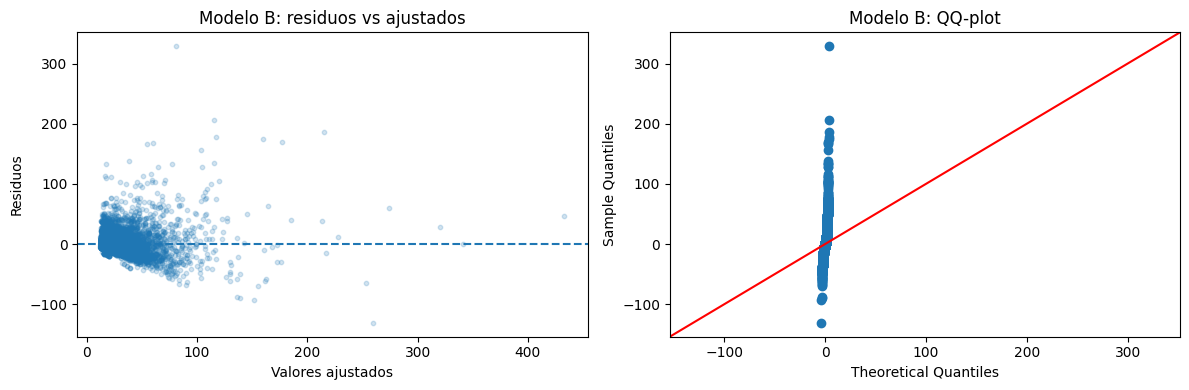

                              OLS Regression Results                              
Dep. Variable:     np.sqrt(total_freight)   R-squared:                       0.543
Model:                                OLS   Adj. R-squared:                  0.543
Method:                     Least Squares   F-statistic:                     2874.
Date:                    Fri, 28 Aug 2026   Prob (F-statistic):               0.00
Time:                            02:49:52   Log-Likelihood:                -21157.
No. Observations:                   14539   AIC:                         4.233e+04
Df Residuals:                       14532   BIC:                         4.238e+04
Df Model:                               6                                         
Covariance Type:                nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------

,Diagnóstico,Valor
0,Breusch-Pagan p-value,0.000
1,Jarque-Bera p-value,0.000
2,Durbin-Watson,1.993
3,Asimetría residuos,1.083
4,Curtosis residuos,9.846


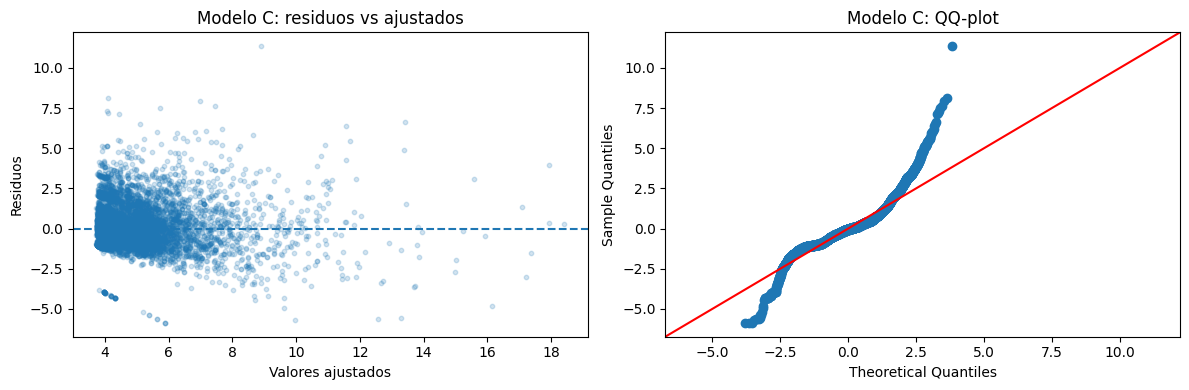


Comparación predictiva fuera de muestra:


,Modelo,MAE,RMSE
0,A,9.095,15.543
1,B,7.420,12.994
2,C,7.051,12.977


In [9]:
# Comparación estadística de los modelos A y B
comparacion_AB = pd.DataFrame({
    "Modelo": ["A", "B"],
    "R2": [modelo_A.rsquared, modelo_B.rsquared],
    "R2_ajustado": [modelo_A.rsquared_adj, modelo_B.rsquared_adj],
    "AIC": [modelo_A.aic, modelo_B.aic],
    "BIC": [modelo_A.bic, modelo_B.bic]
})

display(comparacion_AB)

print("Comparación de modelos anidados A vs B:")
display(anova_lm(modelo_A, modelo_B))

print("\nCoeficientes del Modelo B:")
display(pd.DataFrame({
    "coeficiente": modelo_B.params,
    "p_value": modelo_B.pvalues
}))

# Diagnóstico de multicolinealidad
X_B = pd.DataFrame(
    modelo_B.model.exog,
    columns=modelo_B.model.exog_names
)

vif_B = pd.DataFrame({
    "Variable": X_B.columns,
    "VIF": [
        variance_inflation_factor(X_B.values, i)
        for i in range(X_B.shape[1])
    ]
})

print("\nVIF Modelo B:")
display(vif_B)

# Diagnósticos numéricos de residuos
bp_B = het_breuschpagan(modelo_B.resid, modelo_B.model.exog)
jb_B = jarque_bera(modelo_B.resid)
dw_B = durbin_watson(modelo_B.resid)

diagnosticos_B = pd.DataFrame({
    "Diagnóstico": [
        "Breusch-Pagan p-value",
        "Jarque-Bera p-value",
        "Durbin-Watson"
    ],
    "Valor": [bp_B[1], jb_B[1], dw_B]
})

display(diagnosticos_B)

# Diagnósticos gráficos del Modelo B
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].scatter(modelo_B.fittedvalues, modelo_B.resid, alpha=0.20, s=10)
ax[0].axhline(0, linestyle="--")
ax[0].set_xlabel("Valores ajustados")
ax[0].set_ylabel("Residuos")
ax[0].set_title("Modelo B: residuos vs ajustados")

sm.qqplot(modelo_B.resid, line="45", ax=ax[1])
ax[1].set_title("Modelo B: QQ-plot")

plt.tight_layout()
plt.show()

# Modelo C
# Se transforma la respuesta con raíz cuadrada para reducir asimetría y se agregan
# dos interacciones que permiten que el efecto de peso y volumen varíe con n_items.
modelo_C = smf.ols(
    """
    np.sqrt(total_freight)
    ~ total_price
    + total_weight_g
    + total_volume_cm3
    + n_items
    + total_weight_g:n_items
    + total_volume_cm3:n_items
    """,
    data=freight_data
).fit()

print(modelo_C.summary())

bp_C = het_breuschpagan(modelo_C.resid, modelo_C.model.exog)
jb_C = jarque_bera(modelo_C.resid)
dw_C = durbin_watson(modelo_C.resid)

diagnosticos_C = pd.DataFrame({
    "Diagnóstico": [
        "Breusch-Pagan p-value",
        "Jarque-Bera p-value",
        "Durbin-Watson",
        "Asimetría residuos",
        "Curtosis residuos"
    ],
    "Valor": [bp_C[1], jb_C[1], dw_C, jb_C[2], jb_C[3]]
})

print("\nDiagnósticos Modelo C:")
display(diagnosticos_C)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].scatter(modelo_C.fittedvalues, modelo_C.resid, alpha=0.20, s=10)
ax[0].axhline(0, linestyle="--")
ax[0].set_xlabel("Valores ajustados")
ax[0].set_ylabel("Residuos")
ax[0].set_title("Modelo C: residuos vs ajustados")

sm.qqplot(modelo_C.resid, line="45", ax=ax[1])
ax[1].set_title("Modelo C: QQ-plot")

plt.tight_layout()
plt.show()

# Comparación predictiva en una muestra no usada para ajustar
freight_train, freight_test = train_test_split(
    freight_data,
    test_size=0.20,
    random_state=42
)

modelo_A_train = smf.ols(
    "total_freight ~ total_volume_cm3",
    data=freight_train
).fit()

modelo_B_train = smf.ols(
    """
    total_freight
    ~ total_price
    + total_weight_g
    + total_volume_cm3
    + n_items
    """,
    data=freight_train
).fit()

modelo_C_train = smf.ols(
    """
    np.sqrt(total_freight)
    ~ total_price
    + total_weight_g
    + total_volume_cm3
    + n_items
    + total_weight_g:n_items
    + total_volume_cm3:n_items
    """,
    data=freight_train
).fit()

pred_A = modelo_A_train.predict(freight_test)
pred_B = modelo_B_train.predict(freight_test)

# Para volver a la escala original del costo se eleva al cuadrado la predicción de C.
pred_C = np.maximum(modelo_C_train.predict(freight_test), 0) ** 2

comparacion_pred = pd.DataFrame({
    "Modelo": ["A", "B", "C"],
    "MAE": [
        mean_absolute_error(freight_test["total_freight"], pred_A),
        mean_absolute_error(freight_test["total_freight"], pred_B),
        mean_absolute_error(freight_test["total_freight"], pred_C)
    ],
    "RMSE": [
        root_mean_squared_error(freight_test["total_freight"], pred_A),
        root_mean_squared_error(freight_test["total_freight"], pred_B),
        root_mean_squared_error(freight_test["total_freight"], pred_C)
    ]
})

print("\nComparación predictiva fuera de muestra:")
display(comparacion_pred)


**Recomendación final**

No estoy de acuerdo con la afirmación de que el Modelo B sea necesariamente mejor solo porque tiene más variables y un \(R^2\) mayor. En regresión múltiple el \(R^2\) tiende a aumentar al incorporar predictores, aunque estos aporten poco. Por eso es más informativo revisar el \(R^2\) ajustado, AIC, BIC, significancia de los coeficientes, diagnósticos de residuos y, cuando interesa predecir, el error en datos no utilizados para ajustar el modelo.

En este caso B sí mejora de manera importante respecto de A. El \(R^2\) ajustado pasa aproximadamente de **0,410 a 0,581**, mientras que AIC y BIC disminuyen de forma marcada. La comparación de modelos anidados también muestra que las variables adicionales aportan información conjunta. Por lo tanto, la mejora de B no se justifica por “tener más variables”, sino porque el conjunto adicional de predictores explica una fracción relevante de la variabilidad del costo de despacho.

Dos coeficientes son especialmente fáciles de interpretar. El coeficiente de `total_weight_g` es aproximadamente **0,00156**: manteniendo constantes precio, volumen y número de ítems, un aumento de 1.000 gramos se asocia con un incremento promedio cercano a **1,56 unidades monetarias** en el costo de despacho. El coeficiente de `n_items` es aproximadamente **11,71**: manteniendo constantes las demás variables, agregar un ítem se asocia con un aumento promedio cercano a **11,71 unidades monetarias** en `total_freight`. Estas interpretaciones son condicionales al resto de variables del modelo y no deben leerse como efectos causales.

Los VIF de los predictores se mantienen en niveles moderados, por lo que no aparece una multicolinealidad severa. El problema principal de B está en los residuos. El gráfico de residuos versus valores ajustados muestra una dispersión que no es completamente constante y la prueba de Breusch-Pagan rechaza homocedasticidad. El QQ-plot y Jarque-Bera también muestran desviaciones importantes respecto de normalidad, especialmente por colas y observaciones extremas. Durbin-Watson es cercano a 2, por lo que no aparece una señal fuerte de autocorrelación en el orden de las observaciones.

El **Modelo C** usa una transformación de raíz cuadrada sobre `total_freight` y agrega interacciones entre `n_items` con peso y volumen. La transformación busca reducir la fuerte asimetría de una variable positiva como el costo de despacho, mientras que las interacciones permiten que el efecto de peso y volumen no sea exactamente el mismo para pedidos con distinto número de ítems. La distribución de los residuos mejora en asimetría y curtosis, aunque la heterocedasticidad no desaparece completamente. Esto es importante: C es una mejora, pero los diagnósticos todavía indican que el modelo lineal no representa perfectamente toda la estructura de los datos.

Para comparar capacidad predictiva se reservó 20% de los pedidos como prueba. A entrega aproximadamente **MAE 9,10 y RMSE 15,54**, B mejora a **MAE 7,42 y RMSE 12,99**, y C obtiene cerca de **MAE 7,05 y RMSE 12,98**. Con estos resultados recomendaría **C** entre las tres alternativas, porque mantiene interpretabilidad, mejora el error típico fuera de muestra y reduce parte de los problemas de distribución observados en B. De todos modos, no lo consideraría un modelo definitivo: la heterocedasticidad residual sugiere que en un trabajo posterior convendría estudiar errores estándar robustos, ponderación o una familia de modelos que represente mejor la varianza del costo.


---

# Tercer Bloque (30 puntos)

El objetivo ahora es distinto:

> Al momento de procesar un pedido, queremos estimar el riesgo de que llegue después de la fecha comprometida.

El analista ajustó inicialmente el siguiente modelo:


In [10]:
logit_data = delivered[
    delivered["late_delivery"].notna()
    & delivered["total_price"].notna()
    & delivered["total_freight"].notna()
    & delivered["n_items"].notna()
    & delivered["n_categories"].notna()
    & delivered["days_to_carrier"].notna()
    & delivered["remaining_days"].notna()
    & delivered["approval_hours"].notna()
].copy()

modelo_riesgo_1 = smf.logit(
    """
    late_delivery
    ~ total_price
    + total_freight
    + n_items
    + n_categories
    + days_to_carrier
    + remaining_days
    + approval_hours
    + C(is_weekend_purchase)
    """,
    data=logit_data
).fit()

print(modelo_riesgo_1.summary())


Optimization terminated successfully.
         Current function value: 0.258033
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:          late_delivery   No. Observations:                14538
Model:                          Logit   Df Residuals:                    14529
Method:                           MLE   Df Model:                            8
Date:                Fri, 28 Aug 2026   Pseudo R-squ.:                 0.08154
Time:                        02:49:52   Log-Likelihood:                -3751.3
converged:                       True   LL-Null:                       -4084.3
Covariance Type:            nonrobust   LLR p-value:                1.429e-138
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      -1.2893      0.220     -5.857      0.000   

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     13362
           1       0.74      0.06      0.11      1176

    accuracy                           0.92     14538
   macro avg       0.83      0.53      0.54     14538
weighted avg       0.91      0.92      0.89     14538



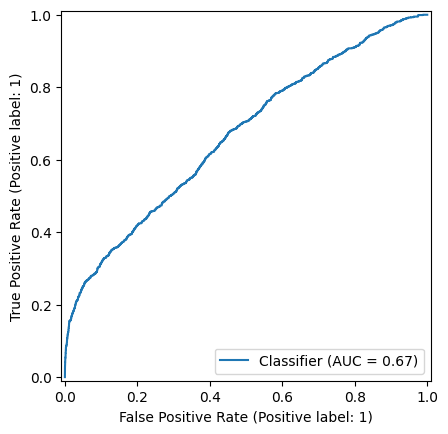

In [11]:
logit_data["prob_1"] = modelo_riesgo_1.predict(logit_data)
logit_data["pred_1"] = (logit_data["prob_1"] >= 0.5).astype(int)

print(classification_report(
    logit_data["late_delivery"].astype(int),
    logit_data["pred_1"]
))

RocCurveDisplay.from_predictions(
    logit_data["late_delivery"].astype(int),
    logit_data["prob_1"]
)

plt.show()


El analista escribe en su informe:

> “El modelo tiene un Accuracy alto, por lo tanto permite detectar correctamente los pedidos que se atrasarán y debería pasar a producción.”


1. identifica qué tipo de modelo utilizó y justificar por qué es o no apropiado para la variable objetivo
2. interpreta correctamente el Odd de la variable `days_to_carrier`
3. evalua la calidad predictiva del modelo utilizando la matriz de confusión, métricas de clasificación y/o curva ROC
4. evalua lo que expuso el analista y determina si es correcto para este problema
5. indica si mantendrías un threshold de `0.5` o si probarías otro valor. No es necesario encontrar un threshold “óptimo”, pero debes justificar tu decisión.

### Tu análisis


Matriz de confusión del Modelo de Riesgo 1:
[[13337    25]
 [ 1103    73]]


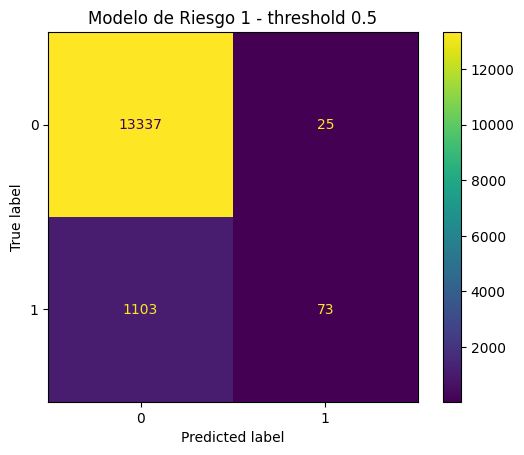

AUC Modelo 1: 0.667

Distribución de la variable objetivo:


,proporción
late_delivery,
0.000,0.919
1.000,0.081


Beta days_to_carrier: 0.1111
Odds Ratio days_to_carrier: 1.1175
Cambio porcentual en los odds: 11.75%


,threshold,accuracy,precision_atraso,recall_atraso,f1_atraso
0,0.050,0.348,0.097,0.850,0.174
1,0.080,0.665,0.126,0.531,0.204
2,0.100,0.780,0.159,0.401,0.228
3,0.150,0.891,0.296,0.252,0.272
4,0.200,0.913,0.413,0.178,0.249
5,0.300,0.922,0.571,0.119,0.197
6,0.400,0.923,0.669,0.086,0.152
7,0.500,0.922,0.745,0.062,0.115


,threshold,accuracy,precision_atraso,recall_atraso,f1_atraso,TN,FP,FN,TP
0,0.080,0.503,0.097,0.616,0.167,1648,1693,113,181
1,0.500,0.919,0.000,0.000,0.000,3341,0,294,0


AUC Modelo de Riesgo 2 en test: 0.565


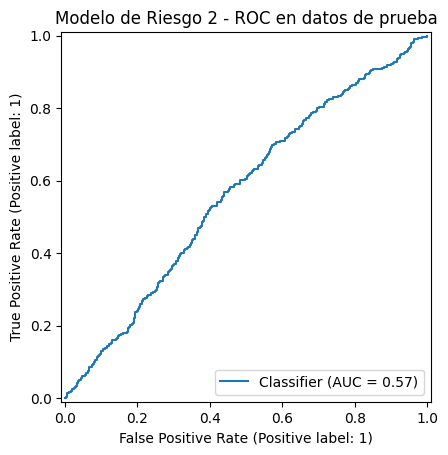

In [12]:
# Matriz de confusión y AUC del modelo entregado por el analista
cm_1 = confusion_matrix(
    logit_data["late_delivery"].astype(int),
    logit_data["pred_1"]
)

print("Matriz de confusión del Modelo de Riesgo 1:")
print(cm_1)

ConfusionMatrixDisplay.from_predictions(
    logit_data["late_delivery"].astype(int),
    logit_data["pred_1"]
)
plt.title("Modelo de Riesgo 1 - threshold 0.5")
plt.show()

auc_1 = roc_auc_score(
    logit_data["late_delivery"].astype(int),
    logit_data["prob_1"]
)

print(f"AUC Modelo 1: {auc_1:.3f}")
print("\nDistribución de la variable objetivo:")
display(
    logit_data["late_delivery"]
    .value_counts(normalize=True)
    .sort_index()
    .rename("proporción")
    .to_frame()
)

# Odds ratio de days_to_carrier
beta_days = modelo_riesgo_1.params["days_to_carrier"]
odds_days = np.exp(beta_days)

print(f"Beta days_to_carrier: {beta_days:.4f}")
print(f"Odds Ratio days_to_carrier: {odds_days:.4f}")
print(f"Cambio porcentual en los odds: {(odds_days - 1) * 100:.2f}%")

# Sensibilidad del resultado al threshold
filas_threshold = []

for threshold in [0.05, 0.08, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]:
    pred = (logit_data["prob_1"] >= threshold).astype(int)

    filas_threshold.append({
        "threshold": threshold,
        "accuracy": accuracy_score(logit_data["late_delivery"], pred),
        "precision_atraso": precision_score(
            logit_data["late_delivery"], pred, zero_division=0
        ),
        "recall_atraso": recall_score(logit_data["late_delivery"], pred),
        "f1_atraso": f1_score(logit_data["late_delivery"], pred)
    })

thresholds = pd.DataFrame(filas_threshold)
display(thresholds)

# Modelo de Riesgo 2
# Para una evaluación más realista se separan datos de entrenamiento y prueba.
# Además se eliminan days_to_carrier y remaining_days porque dependen de un evento
# que ocurre después de la compra y no están disponibles al inicio del pedido.
train_idx, test_idx = train_test_split(
    logit_data.index,
    test_size=0.25,
    random_state=42,
    stratify=logit_data["late_delivery"]
)

riesgo_train = logit_data.loc[train_idx].copy()
riesgo_test = logit_data.loc[test_idx].copy()

modelo_riesgo_2 = smf.logit(
    """
    late_delivery
    ~ total_price
    + total_freight
    + n_items
    + n_categories
    + approval_hours
    + C(is_weekend_purchase)
    """,
    data=riesgo_train
).fit(disp=False)

riesgo_test["prob_2"] = modelo_riesgo_2.predict(riesgo_test)

# Se muestran dos thresholds para evidenciar el compromiso entre alertas y detección.
evaluacion_riesgo_2 = []

for threshold in [0.08, 0.50]:
    pred = (riesgo_test["prob_2"] >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        riesgo_test["late_delivery"].astype(int),
        pred
    ).ravel()

    evaluacion_riesgo_2.append({
        "threshold": threshold,
        "accuracy": accuracy_score(riesgo_test["late_delivery"], pred),
        "precision_atraso": precision_score(
            riesgo_test["late_delivery"], pred, zero_division=0
        ),
        "recall_atraso": recall_score(riesgo_test["late_delivery"], pred),
        "f1_atraso": f1_score(riesgo_test["late_delivery"], pred),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

display(pd.DataFrame(evaluacion_riesgo_2))

auc_2 = roc_auc_score(
    riesgo_test["late_delivery"],
    riesgo_test["prob_2"]
)

print(f"AUC Modelo de Riesgo 2 en test: {auc_2:.3f}")

RocCurveDisplay.from_predictions(
    riesgo_test["late_delivery"].astype(int),
    riesgo_test["prob_2"]
)
plt.title("Modelo de Riesgo 2 - ROC en datos de prueba")
plt.show()


**Recomendación al equipo**

El modelo utilizado por el analista es una **regresión logística binaria**, lo que es apropiado para una variable objetivo como `late_delivery`, que toma valor 1 cuando existe atraso y 0 cuando no existe. La regresión logística no predice directamente una categoría, sino una probabilidad; luego esa probabilidad se transforma en 0 o 1 mediante un threshold.

Para `days_to_carrier`, el coeficiente estimado es aproximadamente **0,111**. Al exponenciarlo se obtiene un odds ratio de **1,118**. Esto significa que, manteniendo constantes las demás variables, **cada día adicional hasta entregar el pedido al transportista multiplica los odds de atraso por 1,118**, equivalente a un aumento aproximado de **11,8% en los odds**. Es importante hablar de odds y no decir directamente que la probabilidad aumenta 11,8 puntos porcentuales.

La conclusión basada en Accuracy no es suficiente. Aproximadamente **91,9% de los pedidos no se atrasa**, por lo que existe un desbalance fuerte de clases. Con threshold 0,5 el Accuracy es cercano a **92,2%**, pero la matriz de confusión muestra que el modelo detecta solamente **73 de 1.176 atrasos**, con un recall cercano a **6,2%** para la clase de interés. En otras palabras, el número global de aciertos es alto principalmente porque el modelo clasifica bien la clase mayoritaria. El AUC es aproximadamente **0,667**, lo que indica cierta capacidad de ordenar pedidos según riesgo, pero está lejos de ser una discriminación fuerte.

No mantendría 0,5 de forma automática. Al disminuir el threshold aumenta fuertemente el recall de los atrasos, aunque también aumentan los falsos positivos. Por ejemplo, alrededor de 0,15 el modelo original logra un mejor equilibrio entre precisión y recall que con 0,5. El threshold debe decidirse según el costo operativo: si no detectar un atraso es más grave que generar una alerta falsa, tiene sentido usar un punto de corte menor.

También hay un problema operativo en el Modelo 1. `days_to_carrier` y `remaining_days` utilizan la fecha en que el pedido llega al transportista, por lo que no están disponibles al inicio de la compra. Si la predicción realmente debe hacerse al procesar inicialmente el pedido, incorporar estas variables introduce información futura respecto del momento de decisión. Por eso se ajustó un **Modelo de Riesgo 2** sin esas variables y con una separación entrenamiento/prueba.

El Modelo 2 obtiene un AUC de aproximadamente **0,565 en datos de prueba**, por lo que su capacidad discriminante es baja. Al usar threshold 0,5 prácticamente no identifica atrasos, y al bajar el threshold aumenta el recall a costa de muchas falsas alarmas. Mi recomendación sería **no pasar ninguno de los dos modelos a producción todavía**. El Modelo 1 tiene mejor discriminación, pero utiliza información que no estaría disponible en el momento planteado y además fue evaluado inicialmente sobre los mismos datos usados para ajustarlo. El Modelo 2 respeta mejor el momento de predicción, pero todavía no tiene suficiente capacidad predictiva. El siguiente paso debería ser incorporar variables disponibles tempranamente que representen mejor la logística, validar en una muestra temporal independiente y recién entonces definir el threshold según el costo de falsos positivos y falsos negativos.


---

# Cuarto Bloque (20 puntos)

El equipo de Operaciones necesita anticipar el número de pedidos que recibirá durante los próximos días para planificar su capacidad.

El analista construyó la siguiente serie diaria utilizando los pedidos observados entre enero y julio de 2018


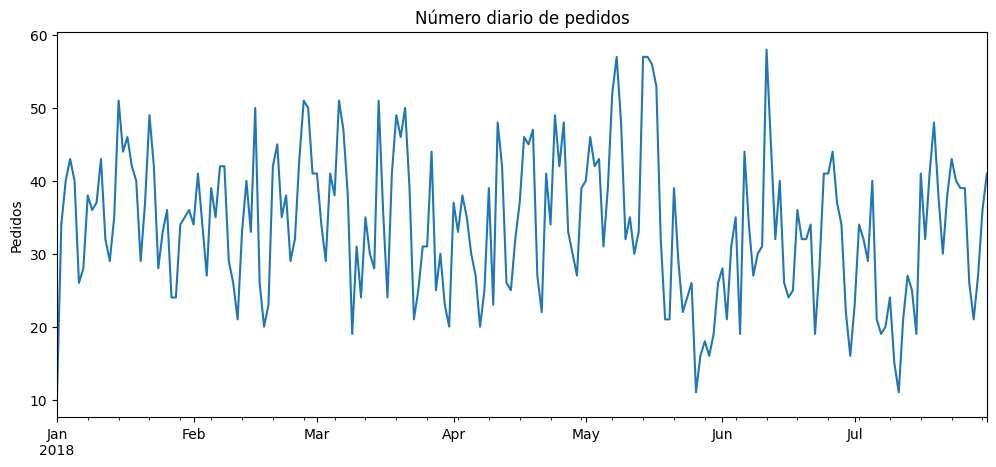

In [13]:
serie_diaria = (
    df
    .dropna(subset=["purchase_date"])
    .groupby("purchase_date")
    .agg(n_orders=("order_id", "nunique"))
    .reset_index()
    .sort_values("purchase_date")
)

serie_diaria = serie_diaria[
    (serie_diaria["purchase_date"] >= "2018-01-01") &
    (serie_diaria["purchase_date"] <= "2018-07-31")
].copy()

serie_diaria.plot(
    x="purchase_date",
    y="n_orders",
    figsize=(12, 5),
    legend=False,
    title="Número diario de pedidos"
)

plt.ylabel("Pedidos")
plt.xlabel("")
plt.show()

In [14]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

serie = (
    serie_diaria
    .set_index("purchase_date")["n_orders"]
    .asfreq("D")
    .fillna(0)
)

print(serie.head())
print(f"Número de días en la serie: {len(serie)}")

purchase_date
2018-01-01    10
2018-01-02    34
2018-01-03    40
2018-01-04    43
2018-01-05    40
Freq: D, Name: n_orders, dtype: int64
Número de días en la serie: 212


Finalmente considera que "test" es la semana que el equipo está pronosticando

In [15]:
train = serie.iloc[:-7]
test = serie.iloc[-7:]

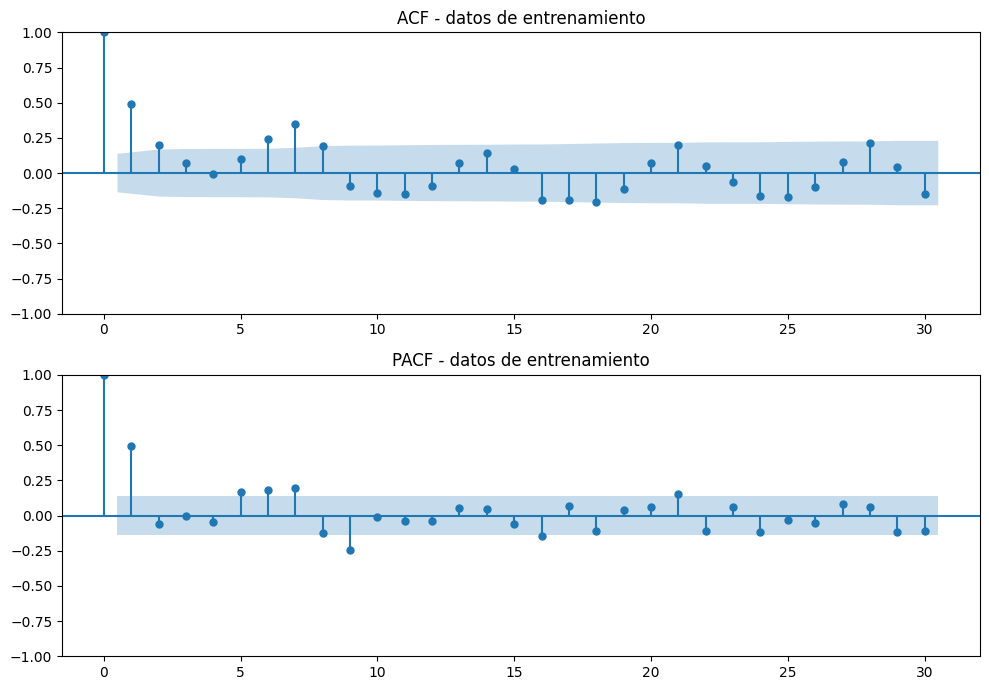

ADF estadístico: -4.060
ADF p-value: 0.0011


                               SARIMAX Results                                
Dep. Variable:               n_orders   No. Observations:                  205
Model:                 ARIMA(7, 0, 7)   Log Likelihood                -698.257
Date:                Fri, 28 Aug 2026   AIC                           1428.515
Time:                        02:49:55   BIC                           1481.683
Sample:                    01-01-2018   HQIC                          1450.020
                         - 07-24-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         33.8169      1.464     23.095      0.000      30.947      36.687
ar.L1         -0.1846      0.102     -1.802      0.072      -0.385       0.016
ar.L2         -0.2430      0.090     -2.715      0.0

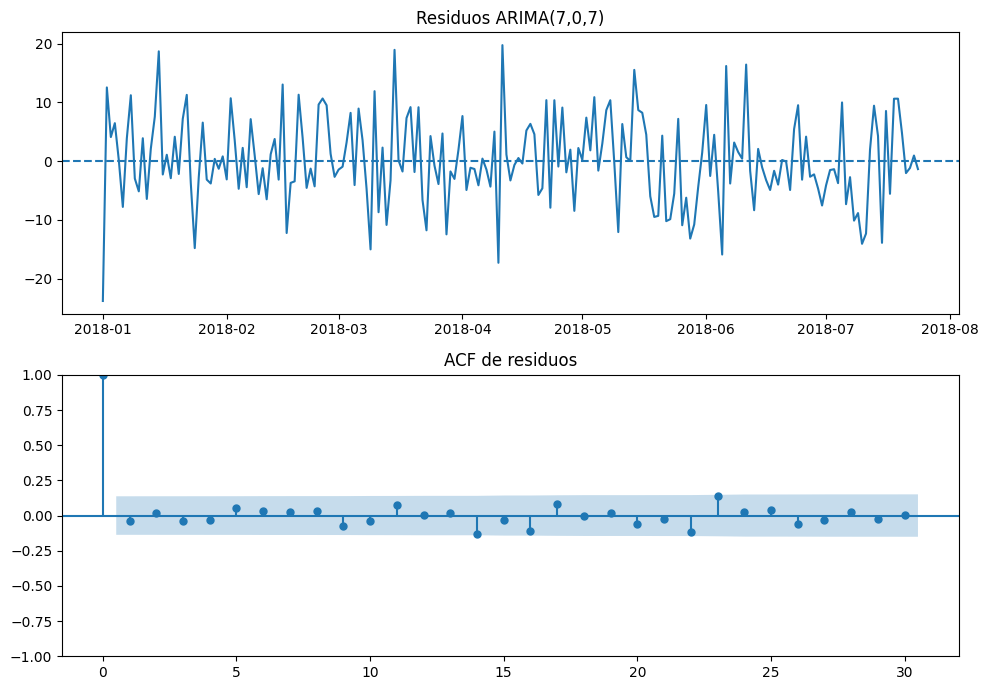

Test de Ljung-Box:


,lb_stat,lb_pvalue
7,2.077,0.955
14,9.044,0.828
21,14.512,0.847


,real,ARIMA_707
2018-07-25,39,35.181
2018-07-26,39,36.511
2018-07-27,26,28.168
2018-07-28,21,26.816
2018-07-29,27,35.699
2018-07-30,36,40.254
2018-07-31,41,38.866


,Modelo,MAE,RMSE
0,"ARIMA(7,0,7)",4.197,4.745
1,Naive semanal,7.286,8.289


In [16]:
# ACF y PACF se revisan sobre train para no usar la semana reservada como test.
fig, ax = plt.subplots(2, 1, figsize=(10, 7))

plot_acf(train, lags=30, ax=ax[0])
plot_pacf(train, lags=30, ax=ax[1], method="ywm")

ax[0].set_title("ACF - datos de entrenamiento")
ax[1].set_title("PACF - datos de entrenamiento")

plt.tight_layout()
plt.show()

# Test ADF como apoyo para evaluar estacionariedad
adf_stat, adf_p, *_ = adfuller(train)
print(f"ADF estadístico: {adf_stat:.3f}")
print(f"ADF p-value: {adf_p:.4f}")

# Ajuste solicitado por el enunciado
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    modelo_707 = ARIMA(
        train,
        order=(7, 0, 7)
    ).fit(method_kwargs={"maxiter": 500})

print(modelo_707.summary())
print("Convergencia:", modelo_707.mle_retvals.get("converged"))

# Diagnóstico de residuos
residuos_707 = modelo_707.resid.dropna()

fig, ax = plt.subplots(2, 1, figsize=(10, 7))

ax[0].plot(residuos_707)
ax[0].axhline(0, linestyle="--")
ax[0].set_title("Residuos ARIMA(7,0,7)")

plot_acf(residuos_707, lags=30, ax=ax[1])
ax[1].set_title("ACF de residuos")

plt.tight_layout()
plt.show()

ljung_box = acorr_ljungbox(
    residuos_707,
    lags=[7, 14, 21],
    return_df=True
)

print("Test de Ljung-Box:")
display(ljung_box)

# Pronóstico de la semana reservada
forecast_707 = modelo_707.forecast(steps=7)

comparacion_pronostico = pd.DataFrame({
    "real": test,
    "ARIMA_707": forecast_707
})

display(comparacion_pronostico)

mae_707 = mean_absolute_error(test, forecast_707)
rmse_707 = root_mean_squared_error(test, forecast_707)

# Benchmark simple: repetir la semana anterior
naive_semanal = pd.Series(
    train.iloc[-7:].values,
    index=test.index
)

mae_naive = mean_absolute_error(test, naive_semanal)
rmse_naive = root_mean_squared_error(test, naive_semanal)

comparacion_metricas = pd.DataFrame({
    "Modelo": ["ARIMA(7,0,7)", "Naive semanal"],
    "MAE": [mae_707, mae_naive],
    "RMSE": [rmse_707, rmse_naive]
})

display(comparacion_metricas)


> El analista sostiene que la cantidad de pedidos de un día depende de lo ocurrido en los últimos 7 anteriores, y que bastaría un ARIMA(7,0,7)


1. Utilice ACF y PACF para evaluar si la elección de un ARIMA(7,0,7) está justificada a priori.

2. Ajuste el modelo y evalúe sus diagnósticos. ¿Encuentra evidencia de problemas importantes en los residuos?

3. Compare el pronóstico con los últimos 7 días reales. Considerando conjuntamente ACF/PACF, diagnósticos y capacidad predictiva, ¿apoyaría el trabajo del analista? Justifique.

**Respuesta e interpretación**

**1. Elección a priori de ARIMA(7,0,7).** La justificación del analista no es correcta como criterio de selección. Que una semana tenga siete días no implica que el proceso necesite siete términos autorregresivos y siete términos de medias móviles. Los órdenes \(p\) y \(q\) deben sugerirse a partir de la estructura de ACF y PACF. En los datos de entrenamiento la ACF presenta una correlación fuerte en el rezago 1 y también señales en torno a los rezagos 6 y 7; la PACF también muestra algunos rezagos significativos, pero no existe un corte limpio que justifique directamente \(p=7\) y \(q=7\). La señal en el rezago 7 puede ser compatible con una estructura semanal, lo que conceptualmente también podría estudiarse con un componente estacional. Como apoyo, la prueba ADF entrega un p-value cercano a **0,0011**, por lo que no aparece evidencia de una raíz unitaria y usar \(d=0\) es razonable para este tramo.

**2. Diagnóstico del ARIMA(7,0,7).** El modelo se ajustó aumentando el número máximo de iteraciones y logró converger. Después del ajuste, los residuos no presentan autocorrelaciones importantes en la ACF. El test de Ljung-Box entrega p-values mayores que 0,05 en los rezagos 7, 14 y 21, por lo que no se rechaza la hipótesis de ausencia de autocorrelación residual. Desde el punto de vista temporal, los residuos se comportan razonablemente como ruido blanco. Esto no demuestra que el modelo sea el único ni el más parsimonioso, pero sí indica que consiguió capturar una parte importante de la dependencia temporal presente en la serie.

**3. Pronóstico de los últimos siete días.** En la semana de prueba el ARIMA(7,0,7) obtiene aproximadamente **MAE = 4,20 pedidos** y **RMSE = 4,75 pedidos**. Como referencia, un pronóstico ingenuo que repite los valores de la semana anterior obtiene aproximadamente **MAE = 7,29** y **RMSE = 8,29**, por lo que el ARIMA entrega un mejor pronóstico en esta ventana.

Mi evaluación sería matizada. **No apoyo el razonamiento con el que el analista eligió ARIMA(7,0,7)**, porque los órdenes no se obtienen contando los siete días de la semana. Sin embargo, una vez ajustado, el modelo converge, deja residuos sin autocorrelación evidente y predice esta semana de test mejor que un benchmark sencillo. Por lo tanto, el modelo no debería descartarse, pero tampoco lo declararía definitivo con una sola semana de validación y con 14 términos AR/MA. Lo correcto sería compararlo con alternativas más parsimoniosas y con modelos que representen explícitamente una posible estacionalidad semanal, usando varias ventanas de validación temporal antes de recomendarlo para operación.
